In [1]:
import numpy as np
import torch
import math
from torch import nn
import torch.nn.functional as F
from torch import distributions as pyd

from utils import util
import pandas as pd
import matplotlib as mpl
from matplotlib import pyplot as plt
from sklearn.decomposition import NMF
from maze.MM_Maze_Utils import *
from maze.MM_Plot_Utils import *
from maze.MM_Traj_Utils import *
from sklearn.decomposition import PCA

In [2]:
origin_phi = np.load('./labyrinth/phi_matrix.npy')
print(origin_phi.shape)

(127, 4, 127)


In [3]:
def draw_phi_with_arrow(maze, origin_phi, real_P, dim, n_sa):
    real_P = np.load('./trans_probs(1).npy')
    n_state, n_action = real_P.shape[0], real_P.shape[1]
    feature_dim = 127
    real_P_reshape = real_P.reshape(n_state, n_action, n_state, 1)
    phi_mat = origin_phi.reshape(n_state, n_action, 1, feature_dim)
    aggregate_phi_origin = (real_P_reshape*phi_mat).sum(0).sum(0)

    f = aggregate_phi_origin[:,dim]
    def normalize_sprime(x):
        return (x - np.min(aggregate_phi_origin)) / (np.max(aggregate_phi_origin) - np.min(aggregate_phi_origin))
    f = normalize_sprime(f)
    sprime_cmap = mpl.cm.get_cmap('Purples')
    v_color = sprime_cmap(np.arange(256))
    v_and_color = np.zeros((v_color.shape[0], 4))
    v_and_color[:, 0] = np.linspace(0, 1, 256)
    v_and_color[:, 1:] = v_color[: , :3]
    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    PlotMazeFunction(f, maze, mode='nodes', numcol=None, figsize=4, axes=ax, col=v_and_color)
    
    phi_sa = origin_phi.reshape(n_state * n_action, feature_dim)
    phi_sa_idx = np.argsort(phi_sa, axis=0)[-n_sa:, dim]
    s_idx = phi_sa_idx // n_action
    a_idx = phi_sa_idx % n_action
    s_prime_idx = real_P[s_idx, a_idx, :].argmax(-1)
    assert s_idx.shape == a_idx.shape == s_prime_idx.shape
    r = 0.3
    for i in range(len(s_idx)):
        r_s = maze.ru[s_idx[i]]
        x_s = maze.xc[r_s[-1]]
        y_s = maze.yc[r_s[-1]]
        r_sprime = maze.ru[s_prime_idx[i]]
        x_sprime = maze.xc[r_sprime[-1]]
        y_sprime = maze.yc[r_sprime[-1]]
        delta_x = np.clip(x_sprime - x_s, -0.35, 0.35)
        delta_y = np.clip(y_sprime - y_s, -0.35, 0.35)
        if delta_x == 0 and delta_y == 0:
            ax.annotate(
                '',                     # 不画文本
                xy=(x_sprime-0.2, y_sprime-r),          # 箭头指向（终点）
                xytext=(x_sprime-0.2, y_sprime+r),      # 箭头起点
                arrowprops=dict(
                    arrowstyle='-|>,head_length=0.3,head_width=0.3',   # 箭头样式
                    connectionstyle='arc3,rad=1.5',                # 半圆：rad≈1
                    color='red',
                    lw=1.8
                )
            )   
        else:
            ax.arrow(x_sprime-delta_x*3, y_sprime-delta_y*3, delta_x, delta_y,
                head_width=0.3, head_length=0.2, fc='red', ec='red',
                width=0.1)
    save_path = f'./labyrinth/appendix/origin_phi_{dim}_{n_sa}.pdf'
    plt.savefig(save_path, dpi=400)

/tmp/ipykernel_190755/2112402115.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  sprime_cmap = mpl.cm.get_cmap('Purples')


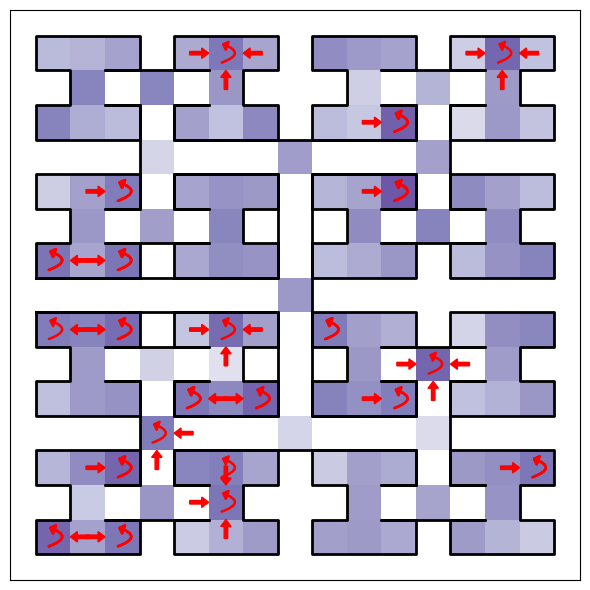

In [6]:
real_P = np.load('./trans_probs(1).npy')
n_state, n_action = real_P.shape[0], real_P.shape[1]
feature_dim = 127
real_P = real_P.reshape(n_state, n_action, n_state, 1)
phi_mat = origin_phi.reshape(n_state, n_action, 1, feature_dim)
aggregate_phi_origin = (real_P*phi_mat).sum(0).sum(0)
maze = NewMaze(6)

draw_phi_with_arrow(maze, origin_phi, real_P, dim=0, n_sa=80)

In [87]:
sorted_normalized_origin_phi = np.sort(normalized_origin_phi.reshape(-1, feature_dim), axis=0)[::-1]
effective_dim_origin = np.where(sorted_normalized_origin_phi>mu+sigma, 1, 0).sum(0)
print(effective_dim_origin)

[ 79  77  61  74  55  82  51  94  78  72  57  96  78  72  72  72  74  86
  70  63  55  84  92  61  68  97  78  98  62  79  70  89  88  78  80  78
  88  54  92  85  70  80  78  82 104  62  60  90  84  74  90  87 101  83
  92  69  89  99  81  75  58  89  59 114  78  88  53  80  98  90  67  83
 108  89  96 101  65  67  75  61 106  78  78 110  96  78  45  86  78  69
  65  90  97  83 101  60  96  86  70 108  90  86  55  67  92  65  96  76
  80  50  63  93  61 106  85  65  87  91  58  92  87  82  71  76  84  75
  92]


In [8]:
agg_r = np.load('aggregate_r.npy')
print(agg_r.shape)
agg_r = agg_r.reshape(3,-1)

(381,)


In [9]:
ground_truth_r = np.load('./reward_shown.npy')
print(ground_truth_r.shape)

(3, 127)


In [10]:
ground_truth_flatten = ground_truth_r.reshape(-1)
agg_r_flatten = agg_r.reshape(-1)
corr = np.corrcoef(ground_truth_flatten, agg_r_flatten)[0, 1]
print(f'Correlation between ground truth and aggregate reward: {corr:.4f}')

Correlation between ground truth and aggregate reward: 0.4207


/tmp/ipykernel_190755/121127032.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  sprime_cmap = mpl.cm.get_cmap(colors[dim])


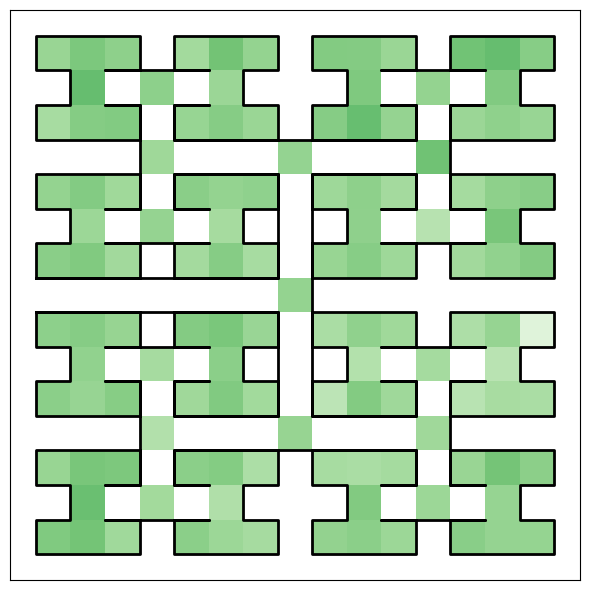

In [13]:
maze = NewMaze(6)
dim=2
f = agg_r[dim]
# f = ground_truth_r[dim]
def normalize(x):
    return (x - np.min(agg_r)) / (np.max(agg_r) - np.min(agg_r))
f = normalize(f)
# f = np.zeros_like(f)
colors = ['Blues', 'Oranges', 'Greens']
sprime_cmap = mpl.cm.get_cmap(colors[dim])
v_color = sprime_cmap(np.arange(256))
# print(f_color.shape)
# print(f_color)
v_and_color = np.zeros((v_color.shape[0], 4))
v_and_color[:, 0] = np.linspace(0, 1, 256)
v_and_color[:, 1:] = v_color[: , :3]
# f[115] = 1
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
# fig, ax = plt.figure(figsize=(6,6))
PlotMazeFunction(f, maze, mode='nodes', numcol=None, figsize=5, axes=ax, col=v_and_color)
plt.savefig(f'./labyrinth/exploration_reward{dim}.pdf', dpi=400)

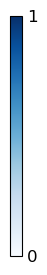

In [ ]:
from matplotlib.colors import BoundaryNorm
from matplotlib.colorbar import ColorbarBase

dim=0
colors = ['Blues', 'Oranges', 'Greens']
# Number of discrete segments
n_segments = 256
sprime_cmap = plt.get_cmap(colors[dim], n_segments)
# Define boundaries for segments (0 to 1 range)
boundaries = np.linspace(0, 1, n_segments + 1)
norm = BoundaryNorm(boundaries, n_segments)

# Create a figure and axis for the colorbar
fig, ax = plt.subplots(figsize=(0.3, 3))
cb = ColorbarBase(
    ax,
    cmap=sprime_cmap,
    norm=norm,
    boundaries=boundaries,
    ticks=np.array([0, 1]),
    spacing='proportional',
    orientation='vertical'
)
cb.ax.tick_params(which='both', length=0)
cb.set_ticklabels(['0', '1'], fontsize=12)
# cb.ax.yaxis.set_visible(False)
# cb.set_label('Discrete Value')
plt.subplots_adjust(left=0.05, right=0.45, top=0.9, bottom=0.1)
# plt.show()
plt.savefig(f'./labyrinth/colorbar{dim}.pdf', dpi=400)


[[ 23  68  77  60  40  86   2  24  35  29]
 [ 23 122  66   1  37  49 112 102   6  26]
 [ 81  23  95  87 120  46   6 108 118  49]]


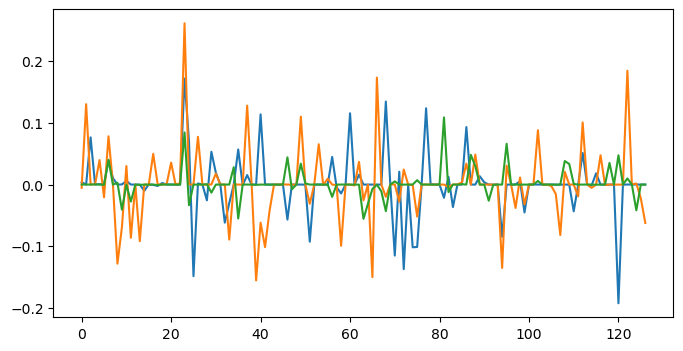

In [ ]:
w = np.load('w.npy')
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
for i in range(3):
    plt.plot(w[i])
w_idx = np.argsort(w,axis=1)[:,::-1]
print(w_idx[:,:10])

In [3]:
maze = NewMaze(6)
dim = 68
action = 1
f = origin_phi[:,action,dim]
def normalize(x):
    return (x - np.min(origin_phi)) / (np.max(origin_phi) - np.min(origin_phi))
f = normalize(f)
sprime_cmap = mpl.cm.get_cmap('Purples')
v_color = sprime_cmap(np.arange(256))
v_and_color = np.zeros((v_color.shape[0], 4))
v_and_color[:, 0] = np.linspace(0, 1, 256)
v_and_color[:, 1:] = v_color[: , :3]
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
PlotMazeFunction(f, maze, mode='nodes', numcol=None, figsize=4, axes=ax, col=v_and_color)
# plt.savefig(f'./labyrinth/origin_phisa_{dim}_{action}.png')
# print(f)

NameError: name 'origin_phi' is not defined

In [8]:
real_P = np.load('./trans_probs(1).npy')
n_state, n_action = real_P.shape[0], real_P.shape[1]
feature_dim = 127
real_P = real_P.reshape(n_state, n_action, n_state, 1)
phi_mat = origin_phi.reshape(n_state, n_action, 1, feature_dim)
aggregate_phi_origin = (real_P*phi_mat).sum(0).sum(0)

5.101054430007935


/tmp/ipykernel_8138/1664685457.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  sprime_cmap = mpl.cm.get_cmap('Purples')


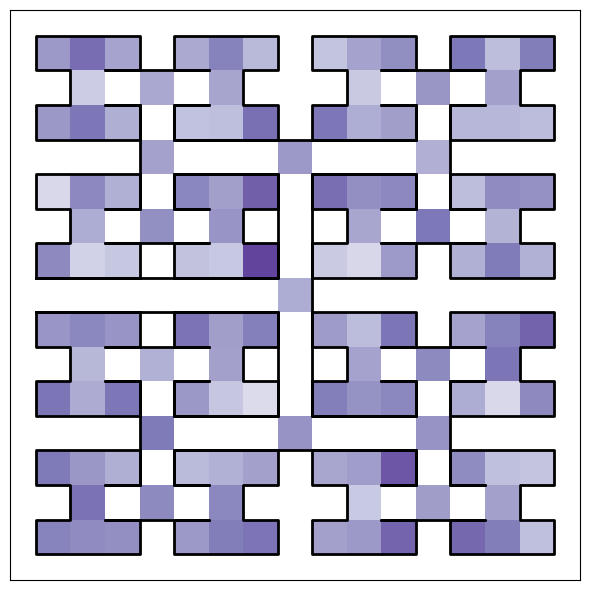

In [9]:
maze = NewMaze(6)
dim = 68
f = aggregate_phi_origin[:,dim]
print(f[28])
def normalize_inside(x):
    return (x - np.min(x)) / (np.max(x) - np.min(x))
def normalize(x):
    return (x - np.min(aggregate_phi_origin)) / (np.max(aggregate_phi_origin) - np.min(aggregate_phi_origin))
f = normalize(f)
sprime_cmap = mpl.cm.get_cmap('Purples')
v_color = sprime_cmap(np.arange(256))
v_and_color = np.zeros((v_color.shape[0], 4))
v_and_color[:, 0] = np.linspace(0, 1, 256)
v_and_color[:, 1:] = v_color[: , :3]
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
PlotMazeFunction(f, maze, mode='nodes', numcol=None, figsize=4, axes=ax, col=v_and_color)
plt.savefig(f'./labyrinth/appendix/origin_phi_sprime_{dim}.png')
# print(f)

In [24]:
print(len(maze.xc))
print(maze.yc)

176
[ 7  7  7  7  7  7  7  7  6  5  4  3  8  9 10 11  3  3  3  3  3  3  3  3
 11 11 11 11 11 11 11 11  2  1  4  5  2  1  4  5 10  9 12 13 10  9 12 13
  1  1  1  1  5  5  5  5  1  1  1  1  5  5  5  5  9  9  9  9 13 13 13 13
  9  9  9  9 13 13 13 13  0  2  0  2  4  6  4  6  0  2  0  2  4  6  4  6
  8 10  8 10 12 14 12 14  8 10  8 10 12 14 12 14  0  0  2  2  0  0  2  2
  4  4  6  6  4  4  6  6  0  0  2  2  0  0  2  2  4  4  6  6  4  4  6  6
  8  8 10 10  8  8 10 10 12 12 14 14 12 12 14 14  8  8 10 10  8  8 10 10
 12 12 14 14 12 12 14 14]


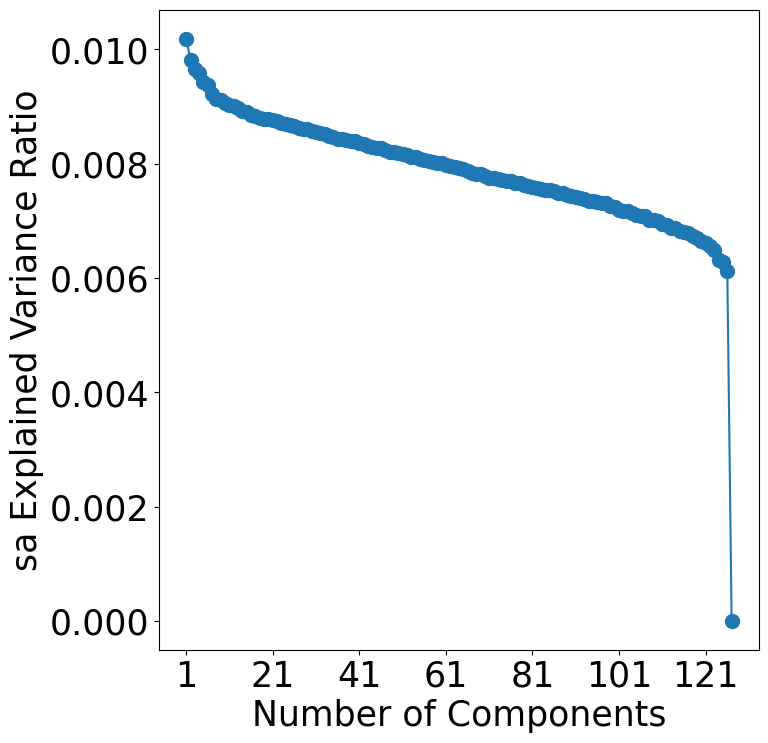

In [29]:
pca = PCA(n_components=127)
flatten_phi = origin_phi.reshape(-1, 127)
# agg_phi_transpose = agg_phi.T # [n_samples, n_features]
flatten_phi_transformed = pca.fit_transform(flatten_phi)
phi_transformed = flatten_phi_transformed.reshape(127,4,127)
evr = pca.explained_variance_ratio_
accum_evr = np.cumsum(evr)
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
plt.plot(np.arange(1, 128), evr, marker='o', markersize=10)
plt.xticks(np.arange(1, 128, 20), fontsize=25)
plt.xlabel('Number of Components', fontsize=25)
plt.yticks(fontsize=25)
plt.ylabel('sa Explained Variance Ratio', fontsize=25)
plt.subplots_adjust(left=0.2, right=0.95, top=0.95, bottom=0.15)
# plt.savefig(f'./labyrinth/saexplained_variance_ratio.pdf', dpi=400)

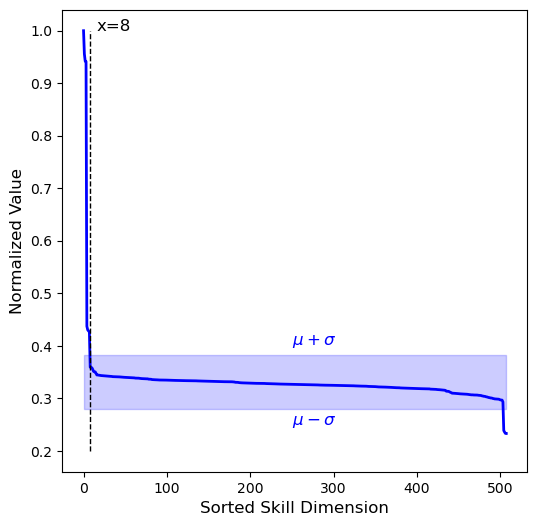

In [89]:
normalized_flatten_phi_transformed = (flatten_phi_transformed - np.min(flatten_phi_transformed))/(np.max(flatten_phi_transformed) - np.min(flatten_phi_transformed))
phi_dim = normalized_flatten_phi_transformed[:,0]
# normalized_phi_dim = (phi_dim - flatten_phi_transformed.min())/(flatten_phi_transformed.max() - flatten_phi_transformed.min())
sort_phi_dim = np.sort(phi_dim)[::-1]
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.plot(np.arange(len(sort_phi_dim)), sort_phi_dim, color='blue', linewidth=2)
ax.vlines(x=8, ymin=0.2, ymax=1, color='k', linestyle='--', linewidth=1)
ax.annotate('x=8', xy=(8, 1), xytext=(15, 1),
            fontsize=12, color='k')
mu = np.mean(normalized_flatten_phi_transformed)
sigma = np.std(normalized_flatten_phi_transformed)
ax.fill_between(np.arange(len(sort_phi_dim)), mu-sigma, mu+sigma, color='blue', alpha=0.2)
ax.annotate('$\mu+\sigma$', xy=(0, mu+sigma), xytext=(250, mu+sigma+0.02),
            fontsize=12, color='blue')
ax.annotate('$\mu-\sigma$', xy=(0, mu-sigma), xytext=(250, mu-sigma-0.03),
            fontsize=12, color='blue')
ax.set_xlabel('Sorted Skill Dimension', fontsize=12)
ax.set_ylabel('Normalized Value', fontsize=12)
plt.savefig('./labyrinth/appendix/pc_skill_curve_0.pdf', dpi=400)

In [90]:
sorted_normalized_phi_transformed = np.sort(normalized_flatten_phi_transformed, axis=0)[::-1]
effective_dim_transformed = np.where(sorted_normalized_phi_transformed>mu+sigma, 1, 0).sum(0)
print(effective_dim_transformed)

[ 8  4 12 12  9 12 20 30 28 36 34 37 37 45 44 44 40 40 46 59 56 46 42 39
 47 43 51 52 57 36 49 48 41 44 33 41 44 47 46 38 44 48 45 28 48 60 55 49
 45 37 52 43 48 47 43 47 40 47 39 46 45 35 42 53 36 54 37 50 33 40 33 61
 40 28 52 43 39 48 41 31 51 38 44 39 21 46 40 51 31 40 36 33 36 48 28 41
 33 40 33 23 35 26 40 25 35 28 33 30 32 24 25 36 23 24 16 17 26 20 18 21
 24 12  8  8  4  4  0]


/tmp/ipykernel_2149/2112402115.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  sprime_cmap = mpl.cm.get_cmap('Purples')


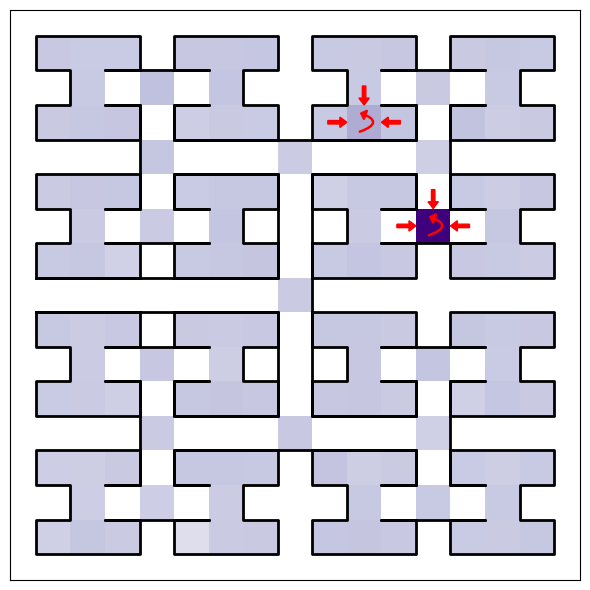

In [ ]:
normalized_phi = normalized_flatten_phi_transformed.reshape(127,4,127)
draw_phi_with_arrow(maze, normalized_phi, real_P, dim=0, n_sa=8)

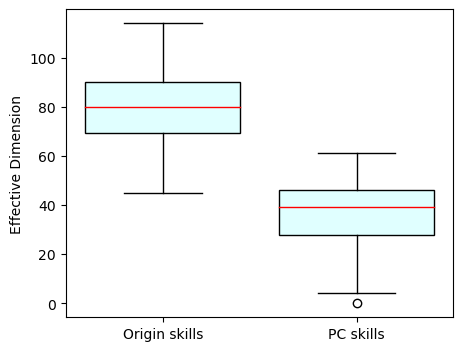

In [94]:
fig, ax = plt.subplots(1, 1, figsize=(5, 4))
ax.boxplot(
    [effective_dim_origin, effective_dim_transformed],
    labels=['Origin skills', 'PC skills'],
    widths=0.8,                    # ← 这里
    patch_artist=True,
    boxprops={'facecolor':'lightcyan','edgecolor':'black'},
    medianprops={'color':'red'}
)
ax.set_ylabel('Effective Dimension', fontsize=10)
plt.savefig(f'./labyrinth/appendix/effective_dim.pdf', dpi=400)

In [93]:
from scipy.stats import ttest_rel

# Perform paired t-test
t_stat, p_value = ttest_rel(effective_dim_origin, effective_dim_transformed)
print(f'T-statistic: {t_stat}, P-value: {p_value}')

T-statistic: 25.507535016223354, P-value: 1.3439322349651696e-51


In [85]:
real_P = np.load('./trans_probs(1).npy')
n_state, n_action = real_P.shape[0], real_P.shape[1]
feature_dim = 127
real_P = real_P.reshape(n_state, n_action, n_state, 1)
phi_mat = phi_transformed.reshape(n_state, n_action, 1, feature_dim)
aggregate_phi_transformed = (real_P*phi_mat).sum(0).sum(0)

In [94]:
print(real_P[115, 3, 57])

[0.]


[[124  74  14  24 122 123  64 120  58  56]
 [120 104  86  43 118 125  54  80  18  10]
 [ 86 125  74  43  62 118  60  63  59  36]]
0.07819598
[[124  65 122 125  29  86 107 123  66  67]
 [126  41  65 124 120  86 104 106  54 125]
 [126 124 120  41  31   8  97  80  24  90]]


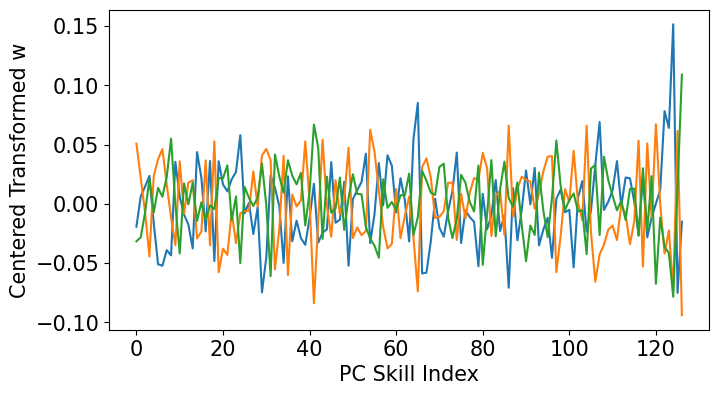

In [78]:
w = np.load('w.npy')
w_transformed = pca.transform(w)
w_transformed_idx = np.argsort(w_transformed, axis=1)[:,::-1]
print(w_transformed_idx[:,:10])
w_transform_centered = w_transformed - np.mean(w_transformed, axis=0)
w_transform_normalized = w_transform_centered / np.std(w_transformed, axis=0)
w_transform_centered_idx = np.argsort(np.abs(w_transform_centered), axis=1)[:,::-1]
print(w_transform_centered[0,122])
print(w_transform_centered_idx[:,:10])
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
for i in range(3):
    plt.plot(w_transform_centered[i, :])
plt.xlabel('PC Skill Index', fontsize=15)
plt.ylabel('Centered Transformed w', fontsize=15)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.subplots_adjust(left=0.2, right=0.95, top=0.95, bottom=0.15)
# plt.savefig(f'./labyrinth/w_transform_centered.pdf', dpi=400)

/tmp/ipykernel_1416/2317257001.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap('Purples')


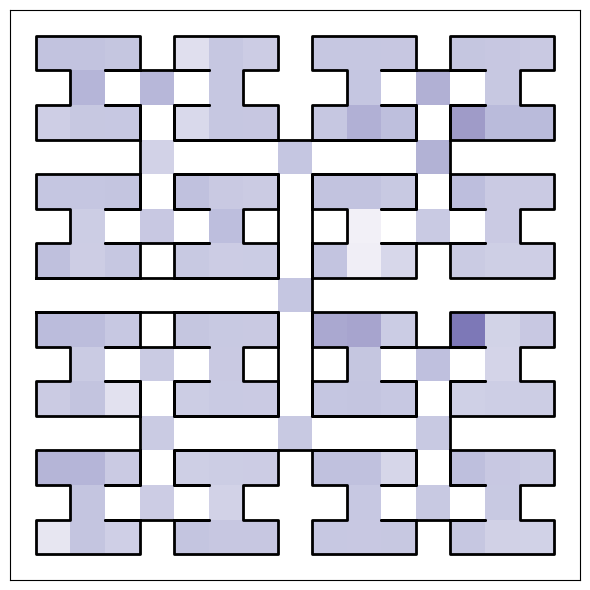

In [ ]:
maze = NewMaze(6)
dim = 24
action = 2
f = phi_transformed[:,action,dim]
def normalize(x):
    return (x - np.min(phi_transformed)) / (np.max(phi_transformed) - np.min(phi_transformed))
f = normalize(f)
sprime_cmap = mpl.cm.get_cmap('Purples')
v_color = sprime_cmap(np.arange(256))
v_and_color = np.zeros((v_color.shape[0], 4))
v_and_color[:, 0] = np.linspace(0, 1, 256)
v_and_color[:, 1:] = v_color[: , :3]
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
PlotMazeFunction(f, maze, mode='nodes', numcol=None, figsize=4, axes=ax, col=v_and_color)
plt.savefig(f'./labyrinth/phisa_{dim}_{action}.pdf', dpi=400)
# print(f)

[[ 23  68  77  60  40  86   2  24  35  29]
 [ 23 122  66   1  37  49 112 102   6  26]
 [ 81  23  95  87 120  46   6 108 118  49]]


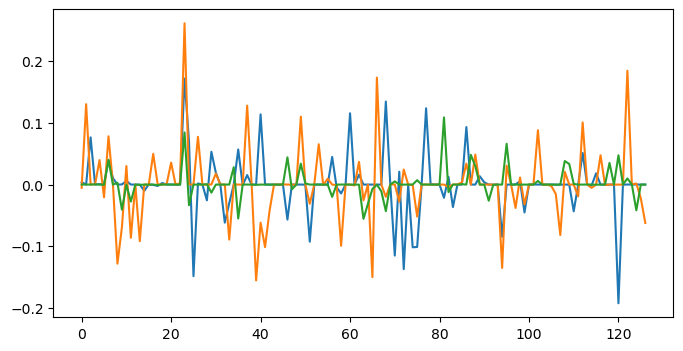

-3.5224644541740417


/tmp/ipykernel_1416/3725024734.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap('Purples')


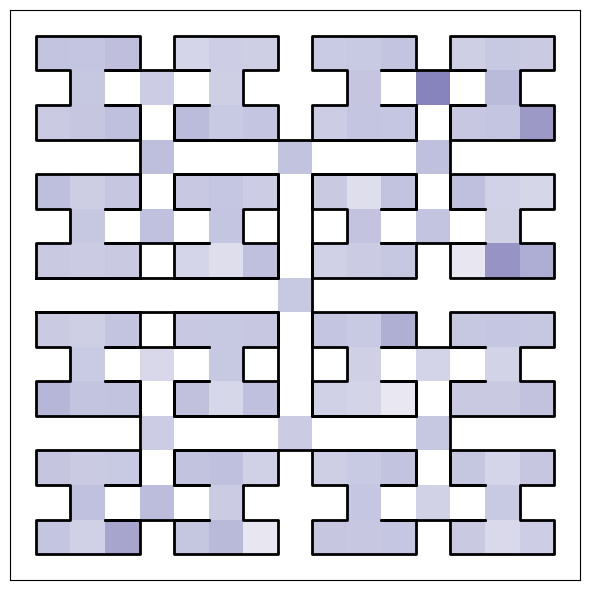

In [ ]:
maze = NewMaze(6)
dim = 68
f = aggregate_phi_transformed[:,dim]
print(f[28])
def normalize_inside(x):
    return (x - np.min(x)) / (np.max(x) - np.min(x))
def normalize(x):
    return (x - np.min(aggregate_phi_transformed)) / (np.max(aggregate_phi_transformed) - np.min(aggregate_phi_transformed))
f = normalize(f)
sprime_cmap = mpl.cm.get_cmap('Purples')
v_color = sprime_cmap(np.arange(256))
v_and_color = np.zeros((v_color.shape[0], 4))
v_and_color[:, 0] = np.linspace(0, 1, 256)
v_and_color[:, 1:] = v_color[: , :3]
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
PlotMazeFunction(f, maze, mode='nodes', numcol=None, figsize=4, axes=ax, col=v_and_color)
plt.savefig(f'./labyrinth/phi_sprime_{dim}.pdf', dpi=400)
# print(f)

In [2]:
agg_phi = np.load('aggregate_phi_realP.npy')
print(agg_phi.shape)
agg_phi = agg_phi
# select_phi = agg_phi[(23, 122, 66, 1, 37, 49, 112, 102, 26, 6), :].sum(0)
# print(select_phi[41])

(127, 127)


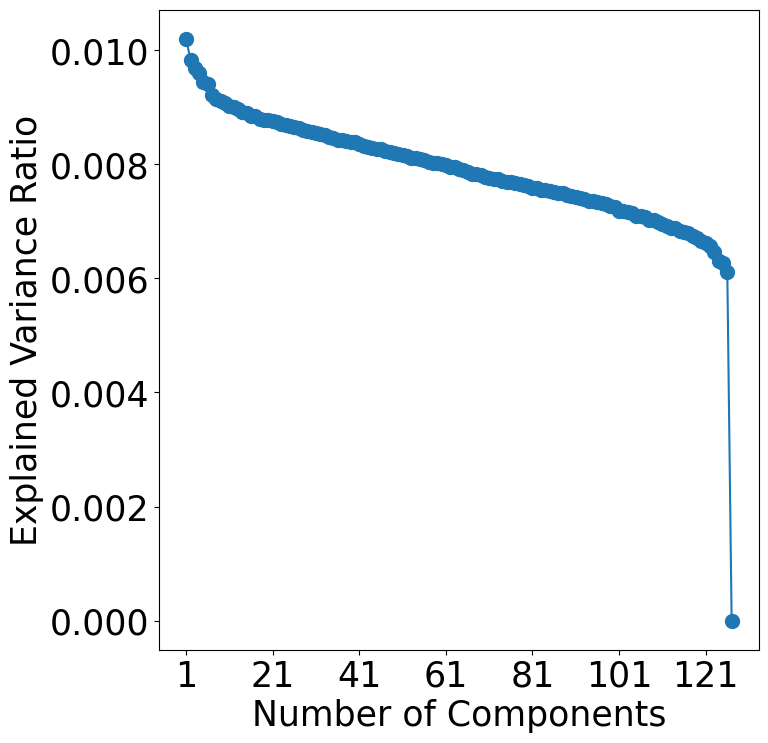

In [3]:
pca = PCA(n_components=127)
agg_phi_transpose = agg_phi.T # [n_samples, n_features]
agg_phi_transformed = pca.fit_transform(agg_phi_transpose)
evr = pca.explained_variance_ratio_
accum_evr = np.cumsum(evr)
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
plt.plot(np.arange(1, 128), evr, marker='o', markersize=10)
plt.xticks(np.arange(1, 128, 20), fontsize=25)
plt.xlabel('Number of Components', fontsize=25)
plt.yticks(fontsize=25)
plt.ylabel('Explained Variance Ratio', fontsize=25)
plt.subplots_adjust(left=0.2, right=0.95, top=0.95, bottom=0.15)
plt.savefig(f'./labyrinth/explained_variance_ratio.pdf', dpi=400)

17.62339162826538 -17.859732151031494
37.5365863813603 -13.822444887182806


/tmp/ipykernel_1416/1500540545.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap('Purples')


[0.31250806 0.32003118 0.30730702 0.32651226 0.31818938 0.32363557
 0.34505696 0.33288799 0.33368648 0.31015295 0.31773097 0.33569856
 0.33356489 0.32484775 0.30935103 0.28710312 0.31948946 0.31104413
 0.31091986 0.32610128 0.31520291 0.33028859 0.30318023 0.31672996
 0.32690478 0.32846098 0.33883088 0.32580718 0.3293406  0.33545386
 0.28775621 0.31688432 0.30250847 0.32737827 0.34031843 0.30927187
 0.31651315 0.34299416 0.32899933 0.31097407 0.33176712 0.33697084
 0.32114155 0.32660452 0.33094307 0.32644128 0.33247007 0.33021189
 0.31795548 0.29609477 0.3119612  0.33713314 0.32619689 0.31891273
 0.32992808 0.33916974 0.32291148 0.32498816 0.32774303 0.32323171
 0.29942783 0.32596925 0.33014385 0.32979932 0.31309823 0.31432831
 0.32243758 0.31049456 0.32454075 0.32183512 0.35407736 0.32874017
 0.35987744 0.3169831  0.32881934 0.31655131 0.30958055 0.31743051
 0.33021206 0.33180687 0.2689056  0.327191   0.32175225 0.3378234
 0.32627721 0.31846983 0.31930704 0.33075299 0.32909837 0.31667

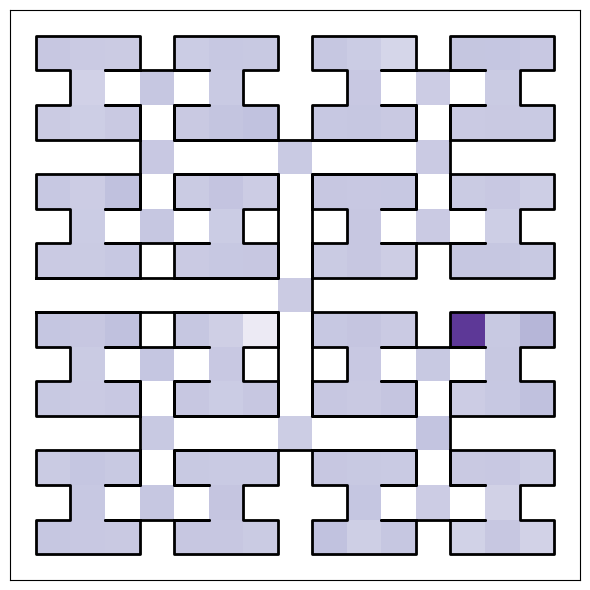

In [ ]:
maze = NewMaze(6)
dim=122
f = agg_phi_transformed[:,dim]
# f = agg_phi[dim]
# f = select_phi
print(np.max(agg_phi), np.min(agg_phi))
print(np.max(f), np.min(f))
def normalize(x):
    return (x - np.min(agg_phi_transformed)) / (np.max(agg_phi_transformed) - np.min(agg_phi_transformed))
f = normalize(f)
# f = np.zeros_like(f)
sprime_cmap = mpl.cm.get_cmap('Purples')
v_color = sprime_cmap(np.arange(256))
# print(f_color.shape)
# print(f_color)
v_and_color = np.zeros((v_color.shape[0], 4))
v_and_color[:, 0] = np.linspace(0, 1, 256)
v_and_color[:, 1:] = v_color[: , :3]
# f[115] = 1
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
# fig, ax = plt.figure(figsize=(6,6))
PlotMazeFunction(f, maze, mode='nodes', numcol=None, figsize=4, axes=ax, col=v_and_color)
plt.savefig(f'./labyrinth/phi_water{dim}.pdf', dpi=400)
print(f)

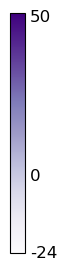

In [ ]:
from matplotlib.colors import BoundaryNorm
from matplotlib.colorbar import ColorbarBase
dim=0
colors = ['Purples']
# Number of discrete segments
n_segments = 256
sprime_cmap = plt.get_cmap(colors[dim], n_segments)
# Define boundaries for segments (0 to 1 range)
boundaries = np.linspace(np.min(agg_phi_transformed), np.max(agg_phi_transformed), n_segments + 1)
norm = BoundaryNorm(boundaries, n_segments)

# Create a figure and axis for the colorbar
fig, ax = plt.subplots(figsize=(0.6, 3))
cb = ColorbarBase(
    ax,
    cmap=sprime_cmap,
    norm=norm,
    boundaries=boundaries,
    ticks=np.array([-24, 0, 50]),
    spacing='proportional',
    orientation='vertical'
)
cb.ax.tick_params(which='both', length=0)
cb.set_ticklabels(['-24','0','50'], fontsize=12)
# cb.ax.yaxis.set_visible(False)
# cb.set_label('Discrete Value')
plt.subplots_adjust(left=0.05, right=0.3, top=0.9, bottom=0.1)
# plt.show()
plt.savefig(f'./labyrinth/purple{dim}.pdf', dpi=400)


[[126 123  58  73 120  14  66 122  56 118]
 [126  86 120 104 118  65 125  18  45  43]
 [126  73  86  58  45 125  65 118  62 104]]
0.08377337442101607
[[123 124  66 122  29 125  86  65  18 107]
 [126  41  18 104 120 106  86  65  32 125]
 [126 123 120  41  80  97   8  42  32  24]]


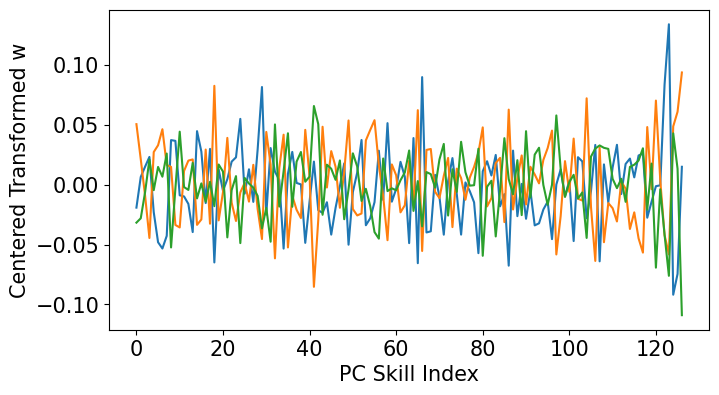

In [18]:
w = np.load('w.npy')
w_transformed = pca.transform(w)
w_transformed_idx = np.argsort(w_transformed, axis=1)[:,::-1]
print(w_transformed_idx[:,:10])
w_transform_centered = w_transformed - np.mean(w_transformed, axis=0)
w_transform_normalized = w_transform_centered / np.std(w_transformed, axis=0)
w_transform_centered_idx = np.argsort(np.abs(w_transform_centered), axis=1)[:,::-1]
print(w_transform_centered[0,122])
print(w_transform_centered_idx[:,:10])
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
for i in range(3):
    plt.plot(w_transform_centered[i, :])
plt.xlabel('PC Skill Index', fontsize=15)
plt.ylabel('Centered Transformed w', fontsize=15)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.subplots_adjust(left=0.2, right=0.95, top=0.95, bottom=0.15)
plt.savefig(f'./labyrinth/w_transform_centered.pdf', dpi=400)

<Axes: >

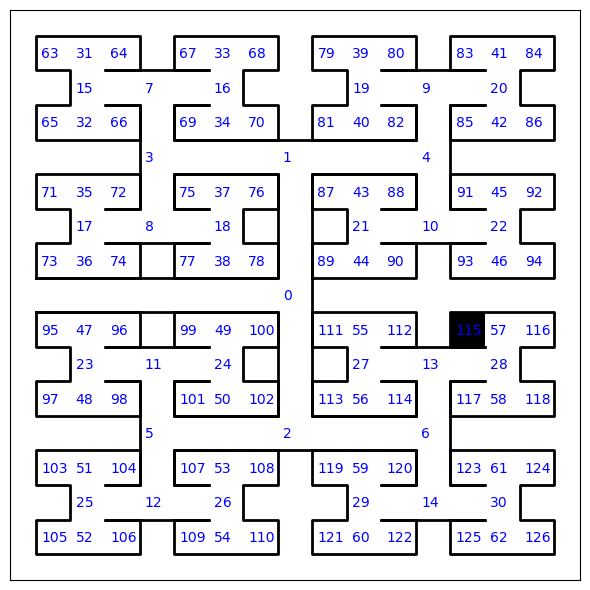

In [7]:
nc = len(maze.xc)
f_cells = np.zeros(nc)
f_cells[115] = 1
fig, ax = plt.subplots(figsize=(6, 6))
# PlotMazeFunction(None,      maze, mode='cells', numcol='blue', axes=ax)
PlotMazeFunction(f_cells,   maze, mode='nodes', numcol='blue', axes=ax)

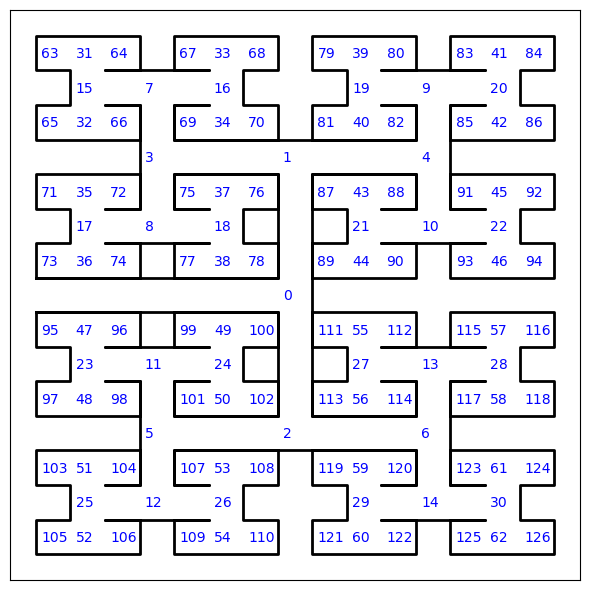

In [8]:
PlotMazeNodes(maze)

(508, 127)


Text(0.5, 1.0, 'corrcoef 0.89')

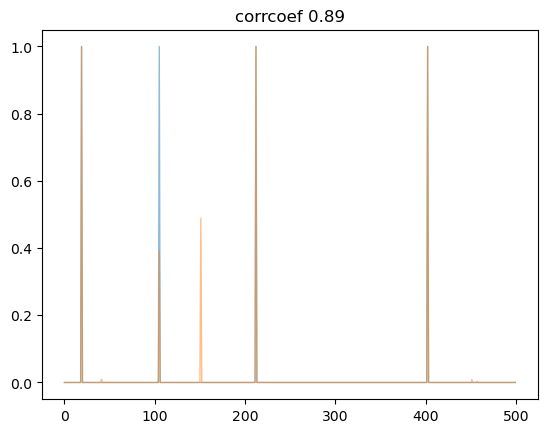

In [17]:
n_state, n_action, n_task = 127, 4, 3
P = np.load('trans_probs.npy').reshape(n_state*n_action, n_state)
print(P.shape)
nmf = NMF(100)
Phi = nmf.fit_transform(P)
Mu = nmf.components_
reconstructed_P = Phi@Mu
plt.plot(P.flatten()[20000:20500], linewidth=1, alpha=0.5)
plt.plot(reconstructed_P.flatten()[20000:20500], linewidth=1, alpha=0.5)
corrcoef = np.corrcoef(P.flatten(), reconstructed_P.flatten())[0,1]
plt.title(f'corrcoef {corrcoef:.2f}')

In [ ]:
R = np.zeros((n_state, n_action, n_task))
R[116,0:3] = 1
R[57,2] = 1

In [3]:
from utils import util, buffer
n_state, n_action, n_task = 9, 4, 9
buffer = torch.load(f'model/RandGridWorld-v0/spedersac/replay_buffer_VI_onehotsa.pkl')
# replay_buffer = buffer.ReplayBuffer(n_state+n_task, n_action, args.buffer_size)
# replay_buffer.load_state_dict(torch.load(f'model/{args.env}/{args.alg}/replay_buffer_VI_onehotsa.pkl'))
# print(f'Replay buffer loaded from model/{args.env}/{args.alg}/replay_buffer_VI_onehotsa.pkl')
# value count
df = {
    'state': np.argmax(replay_buffer.state[:,:n_state], axis=1),
    'action': np.argmax(replay_buffer.action, axis=1),
    'next_state': np.argmax(replay_buffer.next_state[:,:n_state], axis=1),
    'task': np.argmax(replay_buffer.state[:,n_state:], axis=1)
}
import pandas as pd
df = pd.DataFrame(df)
df['s_a_idx'] = df['state']*n_action + df['action']
df = df.groupby(['task']).sum()
print(df)

FileNotFoundError: [Errno 2] No such file or directory: 'model/RandGridWorld-v0/spedersac/replay_buffer_VI_onehotsa.pkl'

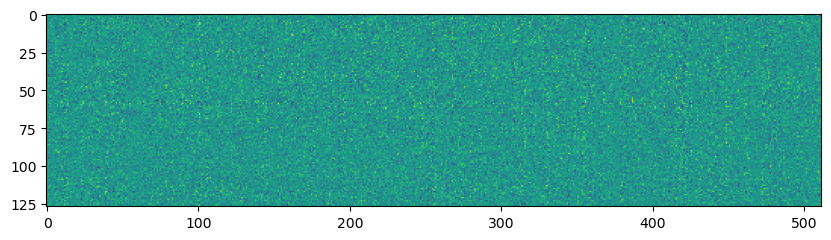

In [ ]:
phi = np.load('./irl_model/labyrinth/spedersac/network_dim512/0/phi_matrix.npy')
mu = np.load('./irl_model/labyrinth/spedersac/network_dim512/0/mu.npy')
fig, ax = plt.subplots(figsize=(10,30))
ax.imshow(phi.reshape(-1,127))
ax.imshow(mu)

In [ ]:
real_P = np.load('trans_probs.npy')
print(real_P.shape)
# print(real_P)
print(np.argmax(real_P[44],1))

(127, 4, 127)
[90 89 21 44]


In [ ]:
dataset = np.load('emissions500new.npy')
segmentation = np.load('learnt_zs_s2.npy')

In [ ]:
print(dataset.shape)
print(segmentation.shape)
# trial * timepoint * s+a  

(238, 500, 2)
(238, 499)


In [ ]:
print(dataset)

[[[ 57   1]
  [116   3]
  [ 57   2]
  ...
  [  6   2]
  [  2   3]
  [  0   3]]

 [[  0   0]
  [  1   1]
  [  4   0]
  ...
  [ 28   0]
  [ 57   1]
  [116   3]]

 [[ 22   2]
  [ 10   1]
  [ 21   1]
  ...
  [ 28   0]
  [ 57   1]
  [116   3]]

 ...

 [[118   2]
  [ 58   1]
  [117   3]
  ...
  [  9   2]
  [  4   3]
  [  1   0]]

 [[  3   0]
  [  8   1]
  [ 17   0]
  ...
  [ 58   1]
  [117   3]
  [ 58   3]]

 [[ 28   1]
  [ 58   1]
  [117   3]
  ...
  [ 49   2]
  [ 24   0]
  [ 49   1]]]


In [4]:
np.unique(dataset[...,1])

NameError: name 'dataset' is not defined

In [5]:
random_buffer = torch.load('./model/labyrinth/spedersac/replay_buffer_labyrinth.pkl')
print(random_buffer.keys())
n_state = 127
n_action = 4
n_task = 3
print(np.argmax(random_buffer['state'][:, :n_state],-1).shape, random_buffer['action'].shape, random_buffer['next_state'].shape)
df = {
    'state_idx': np.argmax(random_buffer['state'][:, :n_state],-1),
    'next_state_idx': np.argmax(random_buffer['next_state'][:, :n_state],-1),
    'action': np.argmax(random_buffer['action'],-1),
    'task': np.argmax(random_buffer['state'][:, n_state:],-1),
}
df = pd.DataFrame(df)
df.to_csv('./model/labyrinth/spedersac/replay_buffer.csv',index=False)


dict_keys(['state', 'action', 'next_state', 'reward', 'done', 'ptr', 'size'])
(118524,) (118524, 4) (118524, 130)


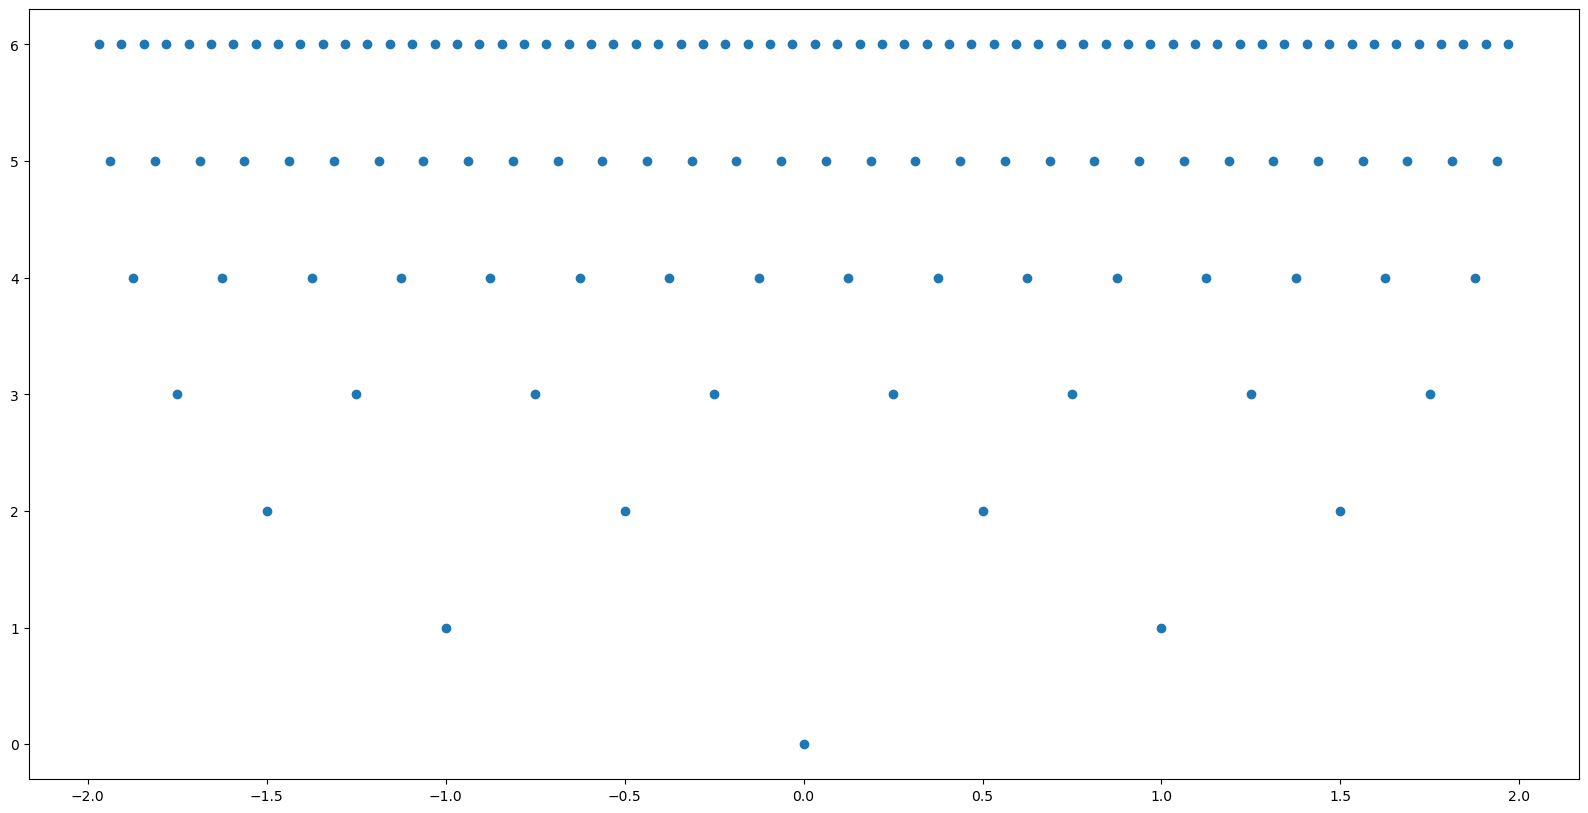

In [6]:
n_state = 127
coordinates = np.zeros((n_state, 2))
def assign_coordinates(index, level, position):
    if index >= n_state:
        return
    y = level
    x = position
    coordinates[index] = (x,y)
    assign_coordinates(2*index+1, level+1, position-1/2**level)
    assign_coordinates(2*index+2, level+1, position+1/2**level)
assign_coordinates(0, 0, 0)
fig, ax = plt.subplots(1,1, figsize=(20,10))
plt.scatter(coordinates[:,0], coordinates[:,1])
    

[14  6 13 ... 28 57 57]
count finished


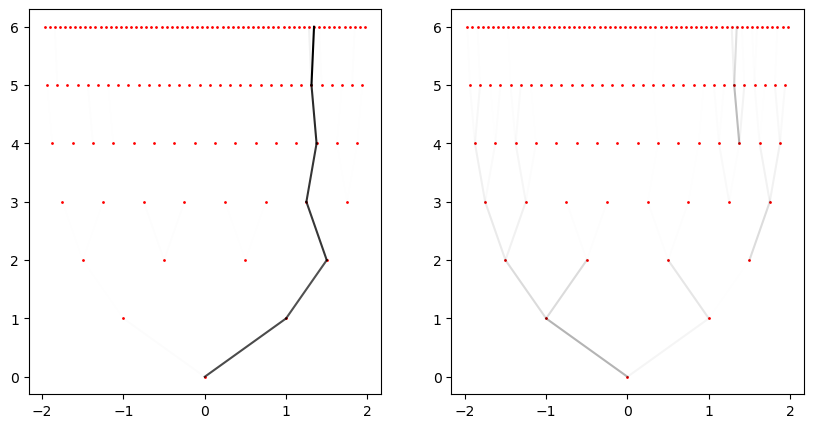

[ 6 28 56 ... 61 30 14]
count finished


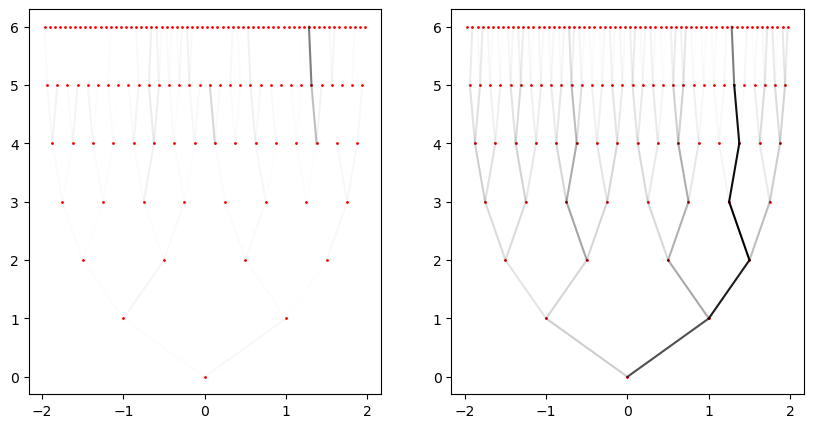

[ 57 116  57 ...  49 100  49]
count finished


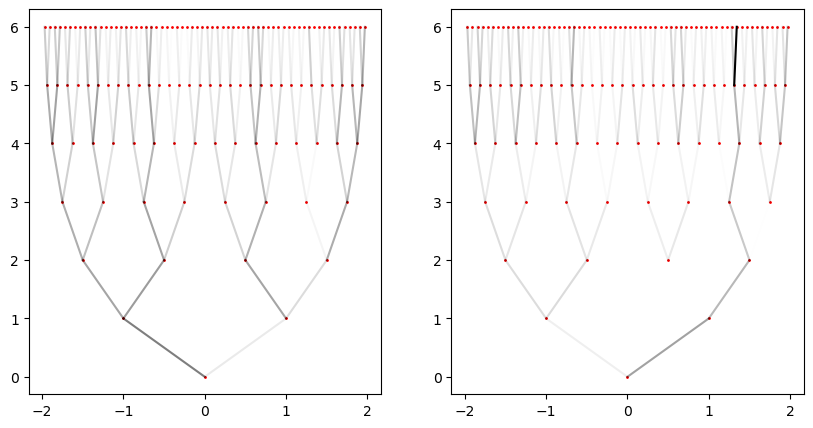

In [7]:

for i in range(3):
    df_task = df[df['task']==i]
    traj = df_task['state_idx'].values
    traj_end = df_task['next_state_idx'].values
    print(traj)
    traj_dir = np.stack([traj, traj_end],-1)
    count = np.zeros((n_state, n_state))
    for q in traj_dir:
        count[q[0], q[1]] += 1
    print('count finished')
    fig, ax = plt.subplots(1,2, figsize=(10,5))
    for j in range(n_state):
        for k in range(n_state):
            if k>=j:
                ax[0].plot([coordinates[j,0], coordinates[k,0]], [coordinates[j,1], coordinates[k,1]], 'k', alpha=count[j,k]/np.max(count))

            else:
                ax[1].plot([coordinates[j,0], coordinates[k,0]], [coordinates[j,1], coordinates[k,1]], 'k', alpha=count[j,k]/np.max(count))
                
    ax[0].scatter(coordinates[:,0], coordinates[:,1], c='r', s=1)
    ax[1].scatter(coordinates[:,0], coordinates[:,1], c='r', s=1)
        # plt.plot(coordinates[q,0], coordinates[q,1], 'r', alpha=0.01)
    plt.show()


In [38]:
import numpy as np
import torch
import gym
import argparse
import os
import pickle
import visualize
from tensorboardX import SummaryWriter
from utils import util, buffer
from agent.spedersac import spedersac_iragent
import pandas as pd

def one_hot(idx, depth):
    return np.eye(depth)[idx]

state_dim = 127
action_dim = 4
n_task = 3
buffer_size = dataset.shape[0] * (dataset.shape[1]-1)
replay_buffer = buffer.ReplayBuffer(state_dim+n_task, action_dim, buffer_size)
state_ar = np.eye(state_dim)
action_ar = np.eye(action_dim)
task_id_ar = np.eye(n_task)
r = np.zeros(1,)
done = np.zeros(1,)
for i in range(dataset.shape[0]):
    for j in range(dataset.shape[1]-2):
        state_onehot = state_ar[dataset[i,j,0]]
        task_id_onehot = task_id_ar[segmentation[i,j]]
        full_state_onehot = np.concatenate([state_onehot, task_id_onehot],-1)
        action_onehot = action_ar[dataset[i,j,1]]
        next_state_onehot = state_ar[dataset[i,j+1,0]]
        next_task_id_onehot = task_id_ar[segmentation[i,j+1]]
        full_next_state_onehot = np.concatenate([next_state_onehot, next_task_id_onehot],-1)
        replay_buffer.add(full_state_onehot, action_onehot, full_next_state_onehot, r, done)

In [40]:
torch.save(replay_buffer.state_dict(), './replay_buffer_labyrinth.pkl')

In [43]:
torch.load('./replay_buffer_random_labyrinth.pkl')

{'state': array([[0., 0., 0., ..., 1., 0., 0.],
        [0., 0., 0., ..., 1., 0., 0.],
        [0., 0., 0., ..., 1., 0., 0.],
        ...,
        [0., 0., 0., ..., 1., 0., 0.],
        [0., 0., 0., ..., 1., 0., 0.],
        [0., 0., 0., ..., 1., 0., 0.]]),
 'action': array([[0., 0., 0., 1.],
        [0., 1., 0., 0.],
        [1., 0., 0., 0.],
        ...,
        [1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [0., 0., 0., 1.]]),
 'next_state': array([[0., 0., 0., ..., 1., 0., 0.],
        [0., 0., 0., ..., 1., 0., 0.],
        [0., 0., 0., ..., 1., 0., 0.],
        ...,
        [0., 0., 0., ..., 1., 0., 0.],
        [0., 0., 0., ..., 1., 0., 0.],
        [0., 0., 0., ..., 1., 0., 0.]]),
 'reward': array([[0.],
        [0.],
        [0.],
        ...,
        [0.],
        [0.],
        [0.]]),
 'done': array([[0.],
        [0.],
        [0.],
        ...,
        [0.],
        [0.],
        [0.]]),
 'ptr': 0,
 'size': 90000}

In [5]:
import numpy as np
import torch
import gym
import argparse
import os
import pickle
import visualize

from tensorboardX import SummaryWriter

from utils import util, buffer
# from agent.sac import sac_agent
# from agent.vlsac import vlsac_agent
# from agent.ctrlsac import ctrlsac_agent
# from agent.diffsrsac import diffsrsac_agent
# from agent.spedersac import spedersac_agent
from agent.spedersac import spedersac_iragent
import pandas as pd

model_path = f'irl_model/RandomGridWorld-v0/spedersac/3x3-f64-onehotsa/0'
state_dim = 2
action_dim = 1
buffer_size = 10000
replay_buffer = buffer.ReplayBuffer(state_dim, action_dim, buffer_size)
buffer_path = model_path.replace('irl_model', 'model')
replay_buffer.load_state_dict(torch.load(f'{buffer_path}/replay_buffer_task1.pkl'))
print(type(replay_buffer))
df = pd.DataFrame({
    'task': np.argmax(replay_buffer.state[:,2:], axis=1),
    'state_i': replay_buffer.state[:,0].astype(int),
    'state_j': replay_buffer.state[:,1].astype(int),
    'action': replay_buffer.action[:,0].astype(int),
    'next_state_i': replay_buffer.next_state[:,0].astype(int),
    'next_state_j': replay_buffer.next_state[:,1].astype(int),
    'reward': replay_buffer.reward[:,0],
    'done': replay_buffer.done[:,0].astype(int)
})
# df.to_csv(f'{buffer_path}/replay_buffer.csv')

<class 'utils.buffer.ReplayBuffer'>


In [6]:
for i in range(9):
    replay_buffer.load_state_dict(torch.load(f'{buffer_path}/replay_buffer_task{i}.pkl'))
    task_id = np.argmax(replay_buffer.state[:,2:], axis=1)
    occupancy = np.zeros((9,))
    for j in range(9):
        occupancy[j] = np.where(task_id == j,1,0).mean()
    print(i, occupancy)
    df = pd.DataFrame({
    'task': np.argmax(replay_buffer.state[:,2:], axis=1),
    'state_i': replay_buffer.state[:,0].astype(int),
    'state_j': replay_buffer.state[:,1].astype(int),
    'action': replay_buffer.action[:,0].astype(int),
    'next_state_i': replay_buffer.next_state[:,0].astype(int),
    'next_state_j': replay_buffer.next_state[:,1].astype(int),
    'reward': replay_buffer.reward[:,0],
    'done': replay_buffer.done[:,0].astype(int)
    })
    df.to_csv(f'{buffer_path}/replay_buffer_task{i}.csv')

0 [1. 0. 0. 0. 0. 0. 0. 0. 0.]
1 [0. 1. 0. 0. 0. 0. 0. 0. 0.]
2 [0. 0. 1. 0. 0. 0. 0. 0. 0.]
3 [0. 0. 0. 1. 0. 0. 0. 0. 0.]
4 [0. 0. 0. 0. 1. 0. 0. 0. 0.]
5 [0. 0. 0. 0. 0. 1. 0. 0. 0.]
6 [0. 0. 0. 0. 0. 0. 1. 0. 0.]
7 [0. 0. 0. 0. 0. 0. 0. 1. 0.]
8 [0. 0. 0. 0. 0. 0. 0. 0. 1.]


In [18]:
np.random.randint(0,9,1)

array([5])

In [25]:
grid_col, grid_row = np.meshgrid(np.arange(3), np.arange(3))
xy = np.array([grid_row.reshape(-1),grid_col.reshape(-1)]).T
print(xy)

[[0 0]
 [0 1]
 [0 2]
 [1 0]
 [1 1]
 [1 2]
 [2 0]
 [2 1]
 [2 2]]


In [9]:
# task_id = df['task']
n_task = 9
state = np.zeros((buffer_size*9, 2+n_task))
action = np.zeros((buffer_size*9, 1))
next_state = np.zeros((buffer_size*9, 2+n_task))
reward = np.zeros((buffer_size*9, 1))
done = np.zeros((buffer_size*9, 1))
for i in range(9):
    replay_buffer.load_state_dict(torch.load(f'{buffer_path}/replay_buffer_task{i}.pkl'))
    state[i*buffer_size:(i+1)*buffer_size] = replay_buffer.state
    action[i*buffer_size:(i+1)*buffer_size] = replay_buffer.action[:,0:1]
    next_state[i*buffer_size:(i+1)*buffer_size] = replay_buffer.next_state
    reward[i*buffer_size:(i+1)*buffer_size] = replay_buffer.reward
    done[i*buffer_size:(i+1)*buffer_size] = replay_buffer.done
replay_buffer = buffer.ReplayBuffer(state_dim, action_dim, buffer_size*9)
replay_buffer.state = state
replay_buffer.action = action
replay_buffer.next_state = next_state
replay_buffer.reward = reward
replay_buffer.done = done
replay_buffer.ptr = buffer_size*9
replay_buffer.size = buffer_size*9
torch.save(replay_buffer.state_dict(), f'{buffer_path}/replay_buffer_balance.pkl')
occupancy = np.zeros((9,))
task_id = np.argmax(replay_buffer.state[:,2:], axis=1)
for j in range(9):
    occupancy[j] = np.where(task_id == j,1,0).mean()
print(occupancy)

[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]


In [3]:
n_width = 3
n_height = 3
n_action = 4
grid_col, grid_row = np.meshgrid(np.arange(n_width), np.arange(n_height))
states = np.concatenate([grid_row.reshape(-1,1), grid_col.reshape(-1,1)], axis=-1)
n_state = n_height * n_width
n_task = n_state
state_action_pairs = np.concatenate([np.repeat(states, n_action, axis=0), np.tile(np.arange(n_action).reshape(-1,1), (states.shape[0],1))], axis=-1)
print(state_action_pairs)

[[0 0 0]
 [0 0 1]
 [0 0 2]
 [0 0 3]
 [0 1 0]
 [0 1 1]
 [0 1 2]
 [0 1 3]
 [0 2 0]
 [0 2 1]
 [0 2 2]
 [0 2 3]
 [1 0 0]
 [1 0 1]
 [1 0 2]
 [1 0 3]
 [1 1 0]
 [1 1 1]
 [1 1 2]
 [1 1 3]
 [1 2 0]
 [1 2 1]
 [1 2 2]
 [1 2 3]
 [2 0 0]
 [2 0 1]
 [2 0 2]
 [2 0 3]
 [2 1 0]
 [2 1 1]
 [2 1 2]
 [2 1 3]
 [2 2 0]
 [2 2 1]
 [2 2 2]
 [2 2 3]]


In [5]:
state_action_pair_idx = (state_action_pairs[:,0]*n_width + state_action_pairs[:,1])*n_action + state_action_pairs[:,2]
print(state_action_pair_idx)

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35]


In [31]:
task_id = np.argmax(buffer['state'][:,state_dim:], axis=1)
occupancy = np.zeros((n_task,))
for j in range(n_task):
    occupancy[j] = np.where(task_id == j,1,0).mean()
print(occupancy)

[0.2 0.2 0.6]


In [30]:
import pandas as pd
buffer = torch.load('./replay_buffer_labyrinth.npy')
print(buffer['state'].shape)

(118524, 131)


In [21]:
import pandas as pd
buffer = torch.load('./replay_buffer_VI.pkl')
print(buffer['state'].shape)
# convert to DataFrame
df = pd.DataFrame({
    'task': np.argmax(buffer['state'][:,2:], axis=1),
    'state_i': buffer['state'][:,0].astype(int),
    'state_j': buffer['state'][:,1].astype(int),
    'action': buffer['action'][:,0].astype(int),
    'next_state_i': buffer['next_state'][:,0].astype(int),
    'next_state_j': buffer['next_state'][:,1].astype(int),
    'reward': buffer['reward'][:,0],
    'done': buffer['done'][:,0].astype(int)
})
df.to_csv('./replay_buffer_VI.csv')


In [24]:
print(df[(df['state_i']==0) & (df['state_j']==0) & (df['action']==0) & (df['task']==2)].shape)
print(df.shape)
occupancy = np.zeros((9,))
task_id = np.argmax(buffer['state'][:,2:], axis=1)
for j in range(9):
    occupancy[j] = np.where(task_id == j,1,0).mean()
print(occupancy)

(445, 8)
(90000, 8)
[0.13661111 0.08794444 0.15526667 0.14611111 0.08668889 0.11876667
 0.05198889 0.06104444 0.15557778]


In [13]:
from torch.nn import functional as F
F.onehot(torch.tensor([1,2,3]), 4)

AttributeError: module 'torch.nn.functional' has no attribute 'onehot'

In [10]:
from agent.spedersac import spedersac_iragent
import visualize
feature_dim = 9
n_width = 3
n_action = 4
n_task = 9
phi = spedersac_iragent.SingleMatrixFixedPhi(n_width, n_action, feature_dim)
phi.load_state_dict({'matrix.weight': torch.FloatTensor(np.load('Phi.npy'))})
print(phi.matrix.weight.shape)
phi_matrix = np.load('Phi.npy')
mu = spedersac_iragent.SingleMatrixFixedMu(n_width, feature_dim)
mu.load_state_dict({'matrix.weight': torch.FloatTensor(np.load('Mu.npy'))})
mu_matrix = np.load('Mu.npy')
print(mu.matrix.weight.shape)
r = np.load('r.npy').reshape(-1, n_task)
print(np.isclose(phi_matrix@(np.linalg.pinv(phi_matrix)@r),r).all())




torch.Size([36, 9])
torch.Size([9, 9])
True


In [2]:
import torch
n_width = n_height = 3
grid_col, grid_row = torch.meshgrid(torch.arange(0, n_width), torch.arange(0, n_height), indexing='xy')
states_all = torch.concat([grid_row.reshape(-1, 1), grid_col.reshape(-1, 1)], -1).float()
actions_all = torch.tensor([[-1,0],[1,0],[0,1],[0,-1]])
state_action_pairs = torch.concat([torch.repeat_interleave(states_all, actions_all.shape[0], dim=0), torch.tile(actions_all, (states_all.shape[0], 1))], -1)
print(state_action_pairs)

tensor([[ 0.,  0., -1.,  0.],
        [ 0.,  0.,  1.,  0.],
        [ 0.,  0.,  0.,  1.],
        [ 0.,  0.,  0., -1.],
        [ 0.,  1., -1.,  0.],
        [ 0.,  1.,  1.,  0.],
        [ 0.,  1.,  0.,  1.],
        [ 0.,  1.,  0., -1.],
        [ 0.,  2., -1.,  0.],
        [ 0.,  2.,  1.,  0.],
        [ 0.,  2.,  0.,  1.],
        [ 0.,  2.,  0., -1.],
        [ 1.,  0., -1.,  0.],
        [ 1.,  0.,  1.,  0.],
        [ 1.,  0.,  0.,  1.],
        [ 1.,  0.,  0., -1.],
        [ 1.,  1., -1.,  0.],
        [ 1.,  1.,  1.,  0.],
        [ 1.,  1.,  0.,  1.],
        [ 1.,  1.,  0., -1.],
        [ 1.,  2., -1.,  0.],
        [ 1.,  2.,  1.,  0.],
        [ 1.,  2.,  0.,  1.],
        [ 1.,  2.,  0., -1.],
        [ 2.,  0., -1.,  0.],
        [ 2.,  0.,  1.,  0.],
        [ 2.,  0.,  0.,  1.],
        [ 2.,  0.,  0., -1.],
        [ 2.,  1., -1.,  0.],
        [ 2.,  1.,  1.,  0.],
        [ 2.,  1.,  0.,  1.],
        [ 2.,  1.,  0., -1.],
        [ 2.,  2., -1.,  0.],
        [ 

In [27]:
import numpy as np
a = np.eye(9).reshape(3,3,9)
print(a[1,0])

[0. 0. 0. 1. 0. 0. 0. 0. 0.]
